# 1. Dataset & DataLoader Overview

Для обучения нейросети необходимо организовать загрузку и предварительную обработку изображений(`Dataset` и `DataLoader`).

В нашей задаче каждый элемент Dataset будет представлять собой пару тензоров: нормализованный канал светлоты `L` и два цветовых канала `ab`, которые выступают в качестве target.

Исходные изображения будут загружаться из PASCALVOC2012 по мере обращения к ним, а списки файлов для train, validation и test возьмём из ранее сохранённых splits.

In [1]:
import numpy as np 
import matplotlib.pyplot as plt
import sys
import torch
from pathlib import Path
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
import os 
project_root = Path.cwd().parent
sys.path.insert(0, str(project_root))
from src.color_utils import prepare_lab, denormalize_lab

In [2]:
train_path = Path('../data/splits/train.txt')
images_dir = Path('../VOCdevkit/VOC2012/JPEGImages')

In [3]:
class ColorizationDataset(Dataset):
    def __init__(self, images_dir, split_path, transform=None):
        super().__init__()
        self.images_dir = images_dir
        self.filenames = split_path.read_text().splitlines()

        self.transform = transform
    def __len__(self):
        return len(self.filenames)
    
    def __getitem__(self, index):
        file_name = self.filenames[index]
        with Image.open(os.path.join(self.images_dir, file_name)) as img:
            rgb_img = img.convert("RGB")

        if self.transform is not None:
            rgb_img = self.transform(rgb_img)
        rgb_img = np.array(rgb_img)

        L_norm, ab_norm = prepare_lab(rgb_img)
        L_norm = torch.tensor(L_norm[np.newaxis, :, :], dtype=torch.float32)
        ab_norm = torch.tensor(np.transpose(ab_norm, (2, 0, 1)), dtype=torch.float32)

        return L_norm, ab_norm

In [4]:
# dataset = ColorizationDataset(images_dir=images_dir, split_path=train_path)

# L_norm, ab_norm = dataset[0]
# print(L_norm.shape, L_norm.dtype)
# print(ab_norm.shape, ab_norm.dtype)

# print()

# transform = transforms.Compose([
#     transforms.Resize(128),
#     transforms.CenterCrop(128)
# ])
# t_dataset = ColorizationDataset(images_dir=images_dir, split_path=train_path, transform=transform)
# L_norm, ab_norm = t_dataset[0]
# print(L_norm.shape, L_norm.dtype)
# print(ab_norm.shape, ab_norm.dtype)

In [5]:
train_path = Path('../data/splits/train.txt')
images_dir = Path('../VOCdevkit/VOC2012/JPEGImages')

train_transform = transforms.Compose([
    transforms.Resize(128),
    transforms.CenterCrop(128)
])
train_dataset = ColorizationDataset(images_dir=images_dir,
                                    split_path=train_path,
                                    transform=train_transform)
train_loader = DataLoader(dataset=train_dataset,
                          batch_size=32,
                          shuffle=True,
                          num_workers=0)

In [6]:
L_batch, ab_batch = next(iter(train_loader))
print(L_batch.shape)
print(ab_batch.shape)

torch.Size([32, 1, 128, 128])
torch.Size([32, 2, 128, 128])


In [7]:
val_path = Path('../data/splits/val.txt')

val_transform = transforms.Compose([
    transforms.Resize(128),
    transforms.CenterCrop(128)
])
val_dataset = ColorizationDataset(images_dir=images_dir,
                                    split_path=val_path,
                                    transform=val_transform)
val_loader = DataLoader(dataset=val_dataset,
                          batch_size=32,
                          shuffle=False,
                          num_workers=0)

In [8]:
L_batch, ab_batch = next(iter(val_loader))
print(L_batch.shape)
print(ab_batch.shape)

torch.Size([32, 1, 128, 128])
torch.Size([32, 2, 128, 128])


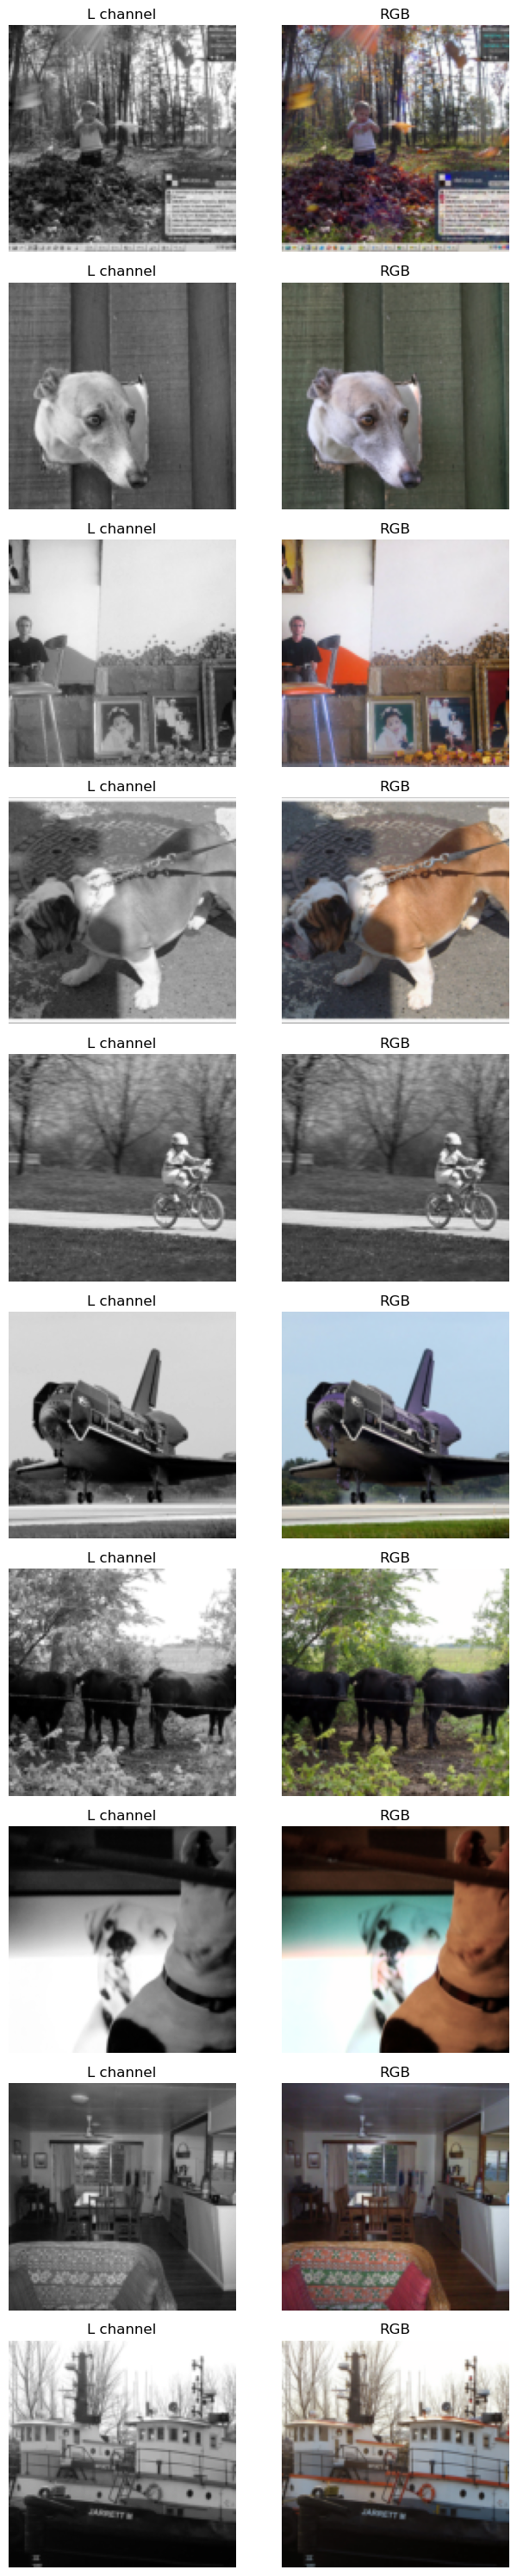

In [9]:
from skimage.color import lab2rgb
fig, axes = plt.subplots(10, 2, figsize=(7, 30))

for i in range(10):
    L = L_batch[i, 0].numpy()
    ab = ab_batch[i].permute(1, 2, 0).numpy()

    lab_img = denormalize_lab(L, ab)
    rgb_img = lab2rgb(lab_img)

    axes[i, 0].imshow(L, cmap="gray", vmin=0, vmax=1)
    axes[i, 0].set_title("L channel")

    axes[i, 1].imshow(np.clip(rgb_img, 0, 1))
    axes[i, 1].set_title("RGB")

    axes[i, 0].axis("off")
    axes[i, 1].axis("off")

plt.tight_layout()
plt.show()